# E-Handel: Snabbrapport

In [1]:
import sys

#Visar vilken py version som används, ska stå med i README
print(sys.version)

#Låter notebook hitta mapp (mapp upp)
sys.path.append("..")

#hämta mina egna funktioner fron src/
from src.io_utils import load_data
from src.metrics import (total_revenue, total_units, aov, revenue_by_category, top_categories, revenue_by_city, revenue_by_month)
from src.viz import plot_revenue_by_category, plot_revenue_by_month

#läser in data med funktionen. ../ används till att gå upp från notebooks/ till projektmappen för att hitta in till data/
df = load_data ("../data/ecommerce_sales.csv")



3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


## Om datan

Datan innehåller 2500 ordrar från 2024-01 -> 2024-06. Fördelat på 5 städer och 6 kategorier.

In [2]:
#df.dtypes kontrollerar data blivit datu
#df.shape kontrollerar hur stor tabellen är
#df.head första fem raderna
print(df.dtypes)
print(df.shape)
df.head()

order_id             int64
date        datetime64[us]
city                   str
category               str
price              float64
units                int64
revenue            float64
dtype: object
(2500, 7)


,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


## Nyckeltal

In [3]:
#räkna ut och visa nyckeltalen
print("Total intäkt:", round(total_revenue(df), 2))
print("Totalt antal enheter:", total_units(df))
print("AOV:", round(aov(df), 2))

Total intäkt: 3502767.23
Totalt antal enheter: 7463
AOV: 1401.11


## 1. Vad säljer vi?

In [4]:
#intäkt per kategori (fråga 1)
revenue_by_category(df).round(2)

category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Home            511070.87
Beauty          163053.97
Toys            143015.99
Name: revenue, dtype: float64

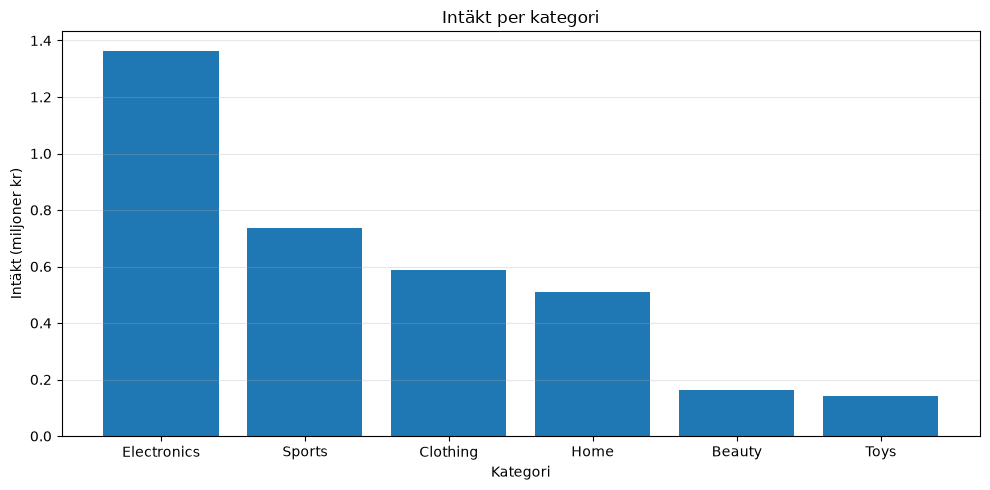

In [5]:
# Stapeldiagram över intäkt per kategori (fråga 1)
plot_revenue_by_category(revenue_by_category(df));

Electronics är den kategorin som driver in mest intäkt. 

Beauty och Toys säljer minst.

## 2. Var säljer vi?

In [6]:
#intäkt per stad (fråga 2)
revenue_by_city(df).round(2)

city
Stockholm    1227201.94
Göteborg      859019.65
Malmö         567926.32
Uppsala       551478.42
Västerås      297140.90
Name: revenue, dtype: float64

Stockholm och Göteborg står för cirka 60% av totalen.

Västerås hamnar på lägst intäkt med cirka 8,5%.

## 3. När säljer vi?

In [7]:
#intäkt per månad (fråga 3)
print(revenue_by_month(df).round(0))

date
2024-01    664083.0
2024-02    548462.0
2024-03    487602.0
2024-04    580195.0
2024-05    632165.0
2024-06    590260.0
Freq: M, Name: revenue, dtype: float64


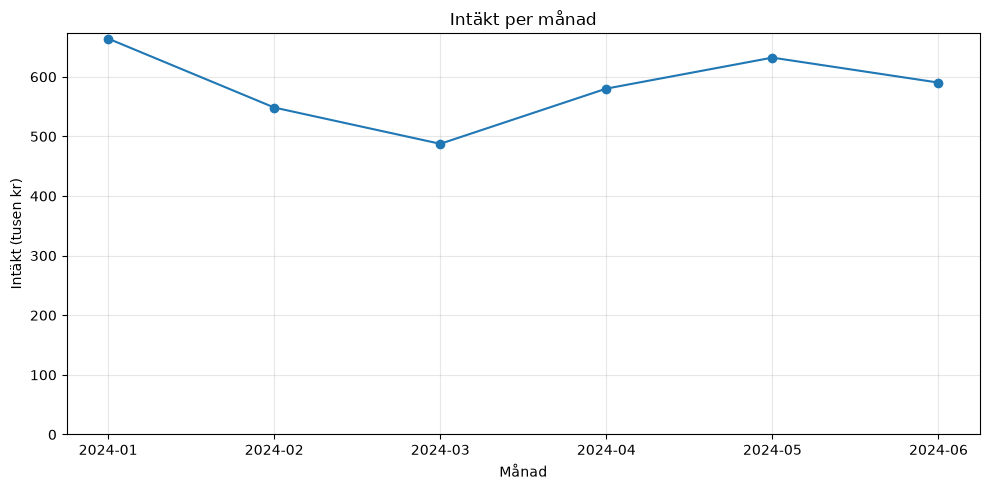

In [8]:
#linjediagram över intäkt per månad (fråga 3)
plot_revenue_by_month(revenue_by_month(df));

Året 2024 startade starkt med högst försäljning och hade en nedåtgående trend fram till mars. 

Efter mars ökade försäljningen igen fram till maj, med en mindre nedgång i juni.

Datan innehåller bara Q1+Q2

## 4. Hur ser en typisk order ut?

In [9]:
#spridning i ordervärde, avrunda, blev mycket siffror när jag inte gjorde det (fråga 4)
df["revenue"].describe().round(2)

count    2500.00
mean     1401.11
std      1166.94
min        50.00
25%       577.96
50%      1088.69
75%      1884.75
max      9192.60
Name: revenue, dtype: float64

* AOV (Average Order Value): Cirka 1401 kr.

* Median: Cirka 1089 kr, hälften av ordrarna är under det.

* Hälften av ordrarna ligger mellan 578 kr och 1885 kr (25% och 75%)

* Minsta order 50 kr och största cirka 9193 kr.

Spridningen är stor (Standardavvikelse cirka 1167 kr). Några få ordrar ökar snittet. En typisk order ligger närmare 1100kr än 1400.

## 5. Topplistor

In [10]:
#topp 3 kategorier intäkt (fråga 5)
top_categories(df).round(2)

category
Electronics    1364228.07
Sports          734653.42
Clothing        586744.91
Name: revenue, dtype: float64

1. Electronics står för cirka 1,36 miljoner kr (39%) av totalen.

2. Sports står för cirka 730 000 kr (21%) av totalen

3. Clothing står för cirka 590 000 kr (17%) av totalen.

Tillsammans står topp 3 för cirka 77% av intäkterna.

## 6. Avvikelser

In [11]:
#kategorisera månad och kategori, intäkt i varje grupp, se svängningar (fråga 6)
df.groupby([df["date"].dt.to_period("M"), "category"])["revenue"].sum().unstack().round(0)

category,Beauty,Clothing,Electronics,Home,Sports,Toys
date,,,,,,
2024-01,36266.0,105282.0,320974.0,65402.0,117601.0,18558.0
2024-02,17229.0,75707.0,294814.0,66959.0,68657.0,25095.0
2024-03,29048.0,75064.0,171968.0,81303.0,104392.0,25826.0
2024-04,21219.0,121693.0,167010.0,97208.0,141835.0,31230.0
2024-05,26729.0,116598.0,197995.0,113173.0,158451.0,19220.0
2024-06,32563.0,92400.0,211467.0,87026.0,143717.0,23088.0


Utifrån resultatet av Q1 + Q2 så halveras nästan Electronics och återhämtar sig sakta till juni men inte fullt tillräckligt.

Vi kan även se att efter februari att Home och Sports ökar men framför allt Sports.

Slutsatsen är att vi bör undersöka varför Electronics tappar så mycket eftersom den genererar mest intäkter. (Tappar Från cirka 295.000 till 172.000 i mars)

## Rekommendationer